<a href="https://colab.research.google.com/github/hyperhacker1/Computational-Intelligence-Lab/blob/main/lab_2_stud.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tensorflow basis

## Example 1

Eager calculations in tensorflow

Add two variables a = 1 and b = 10


In [2]:
# Example
import numpy as np
import tensorflow as tf

print(tf.executing_eagerly())

a = tf.Variable(1)
b = tf.Variable(10)
c = a + b
print(c.numpy())

True
11


## Example 2


In [3]:
# Example
import numpy as np
import tensorflow as tf

@tf.function
def add(a,b):
  return a + b

def sub(a,b):
  return a - b

a = tf.Variable(5)
b = tf.Variable(6)
c = tf.Variable(1)

x = add(a,sub(b,c))
print(x.numpy())


10


# Task 1

Calculate by Tensorflow folowing expression $y = a * b + c$.

a,b, and c are 2x2 matrixes. Numbers in matrixes depends on your choice.
Multiplication is elementwise.


In [4]:
import tensorflow as tf

# Define 2x2 matrices for a, b, and c
a = tf.Variable([[1, 2], [3, 4]])
b = tf.Variable([[5, 6], [7, 4]])
c = tf.Variable([[4, 2], [0, 4]])

# Multiplication is element-wise, so we use tf.multiply or * operator
y = a * b + c
print(y.numpy())

[[ 9 14]
 [21 20]]


# Example 3

Draw a graf of the function $y=f(x)=x^2$ and its derivatice $y'=f'(x). Use Tensoflow for derivative calculation.

[9. 4. 1. 0. 1. 4. 9.]
[-6. -4. -2.  0.  2.  4.  6.]


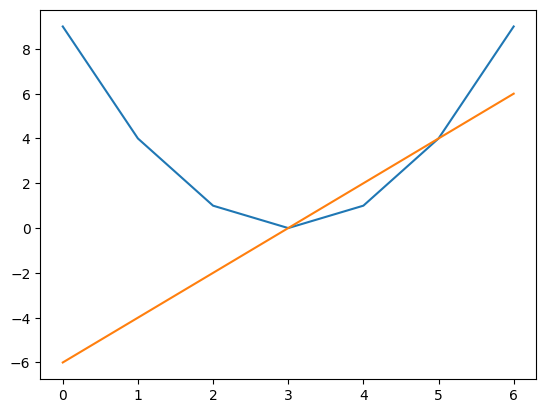

In [5]:
# Example
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

@tf.function
def f(x):
  y = x*x
  return y

@tf.function
def dfdx(x):
  y = f(x)
  return tf.gradients(y, x)[0]

x = tf.Variable([-3.,-2.,-1.,0.,1.,2.,3.])
print(f(x).numpy())
print(dfdx(x).numpy())

plt.plot(f(x))
plt.plot(dfdx(x))

# Task 2

Draw a graf of the function $y=\sigma(x)=\frac{1}{1+e^{-x}}$ and its derivative $y'=s'(x)$. Use Tensoflow for derivative calculation.

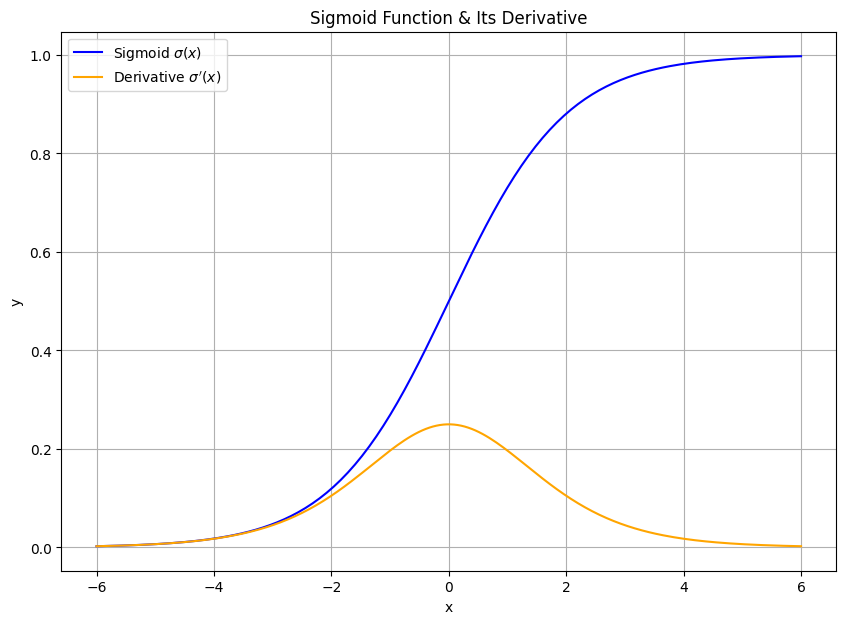

In [6]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Define the sigmoid function
def sigmoid(x):
  return 1.0 / (1.0 + tf.exp(-x))

# Define the gradient of sigmoid using GradientTape
def d_sigmoid(x):
  with tf.GradientTape() as tape:
    tape.watch(x)
    y = sigmoid(x)
  return tape.gradient(y, x)

# Define evaluation range
x_vals = tf.linspace(-6.0, 6.0, 200)

# Compute values
y_vals = sigmoid(x_vals)
dy_vals = d_sigmoid(x_vals)

# Plot results
plt.figure(figsize=(10, 7))
plt.plot(x_vals.numpy(), y_vals.numpy(), label='Sigmoid $\\sigma(x)$', color='blue')
plt.plot(x_vals.numpy(), dy_vals.numpy(), label="Derivative $\\sigma'(x)$", color='orange')
plt.title('Sigmoid Function & Its Derivative')
plt.xlabel('x')
plt.ylabel('y')
plt.grid(True)
plt.legend()
plt.show()

# Task 3

Calculate the gradient of function $y=g(x,y)=e^{-\frac{x^2+y^2}{2\sigma^2}}$ for $\sigma^2 = 0.5\;\mbox{and}\;x = 1\;\mbox{and}\;y = 1$

In [7]:
import tensorflow as tf

# Define inputs and parameter as variables/constants
x = tf.Variable(1.0, dtype=tf.float32)
y = tf.Variable(1.0, dtype=tf.float32)
sigma_sq = tf.constant(0.5, dtype=tf.float32)

# Evaluate gradient using tf.GradientTape
with tf.GradientTape() as tape:
  # Function formulation: g(x,y) = exp( - (x^2 + y^2) / (2 * sigma^2) )
  g = tf.exp(-(x**2 + y**2) / (2 * sigma_sq))

grad = tape.gradient(g, [x, y])
print("Gradient with respect to [x, y]:", [g_val.numpy() for g_val in grad])

Gradient with respect to [x, y]: [np.float32(-0.27067056), np.float32(-0.27067056)]


# Task 4

Create a simple neural feed forward neural network using Tensorflow.

Input layer -> hidden layer -> output layer

for IRIS dataset

In [12]:
import tensorflow as tf
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Load IRIS dataset
try:
  df = pd.read_csv('/content/iris-enc.csv')
except:
  url = "https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data"
  df = pd.read_csv(url, names=['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species'])

# Split features and labels
if 'species' in df.columns:
  X = df.drop('species', axis=1).values
  y = df['species'].values
else:
  X = df.iloc[:, :-1].values
  y = df.iloc[:, -1].values

# Encode target variable
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)
num_classes = len(np.unique(y_encoded))
y_onehot = tf.keras.utils.to_categorical(y_encoded, num_classes=num_classes)

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train test split
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_onehot, test_size=0.2, random_state=42)

# Build feed forward neural network
model = tf.keras.Sequential([
    tf.keras.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(10, activation='relu'),
    tf.keras.layers.Dense(num_classes, activation='softmax')
])

# Compile and train model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
history = model.fit(X_train, y_train, epochs=100, batch_size=8, validation_data=(X_test, y_test), verbose=0)

# Evaluate performance
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"Test Accuracy: {accuracy:.4f}")

Test Accuracy: 1.0000


In [10]:
import tensorflow as tf
import pandas as pd
import numpy as np

# 1. Load the IRIS dataset using pandas
df = pd.read_csv('/content/iris-enc.csv', header=None)

# Extract features (first 4 columns) and labels (one-hot encoded targets from the trailing columns)
X = df.iloc[:, 0:4].values
y_true_classes = np.argmax(df.iloc[:, 4:].values, axis=1)

# 2. Normalize input features (min-max scaling as shown in the example prompt)
max_vals = np.max(X, axis=0)
print("Maximum input values:", max_vals)

X_normalized = X / max_vals
print("\nNormalized inputs:")
print(X_normalized)

# 3. One-hot encode targets using pure TensorFlow
y_onehot = tf.one_hot(y_true_classes, depth=3).numpy()

# 4. Build Feed-Forward Neural Network targeting 3 output classes
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_normalized.shape[1],)),
    tf.keras.layers.Dense(10, activation='relu'),
    tf.keras.layers.Dense(3, activation='softmax')
])

# Display model summary
model.summary()

# 5. Compile and train the model for 500 epochs
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.fit(X_normalized, y_onehot, epochs=500, batch_size=8, verbose=1)

# 6. Predict classes and construct the 3x3 Confusion Matrix using purely NumPy / TensorFlow
y_pred = model.predict(X_normalized)
y_pred_classes = np.argmax(y_pred, axis=1)

# Pure NumPy calculation of 3x3 Confusion Matrix to match notebook example styles
cm = np.zeros((3, 3), dtype=int)
for true, pred in zip(y_true_classes, y_pred_classes):
    cm[true, pred] += 1

print("\nConfussion matrix")
print(cm)

Maximum input values: [7.9 4.4 6.9 2.5]

Normalized inputs:
[[0.64556962 0.79545455 0.20289855 0.08      ]
 [0.62025316 0.68181818 0.20289855 0.08      ]
 [0.59493671 0.72727273 0.1884058  0.08      ]
 [0.58227848 0.70454545 0.2173913  0.08      ]
 [0.63291139 0.81818182 0.20289855 0.08      ]
 [0.6835443  0.88636364 0.24637681 0.16      ]
 [0.58227848 0.77272727 0.20289855 0.12      ]
 [0.63291139 0.77272727 0.2173913  0.08      ]
 [0.55696203 0.65909091 0.20289855 0.08      ]
 [0.62025316 0.70454545 0.2173913  0.04      ]
 [0.6835443  0.84090909 0.2173913  0.08      ]
 [0.60759494 0.77272727 0.23188406 0.08      ]
 [0.60759494 0.68181818 0.20289855 0.04      ]
 [0.5443038  0.68181818 0.15942029 0.04      ]
 [0.73417722 0.90909091 0.17391304 0.08      ]
 [0.72151899 1.         0.2173913  0.16      ]
 [0.6835443  0.88636364 0.1884058  0.16      ]
 [0.64556962 0.79545455 0.20289855 0.12      ]
 [0.72151899 0.86363636 0.24637681 0.12      ]
 [0.64556962 0.86363636 0.2173913  0.12      ]


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 10)             │            50 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 83 (332.00 B)

 Trainable params: 83 (332.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/500
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.2400 - loss: 1.0742      
Epoch 2/500
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.3400 - loss: 1.0299 
Epoch 3/500
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.3400 - loss: 0.9967 
Epoch 4/500
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.3800 - loss: 0.9726 
Epoch 5/500
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4467 - loss: 0.9511 
Epoch 6/500
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5200 - loss: 0.9320 
Epoch 7/500
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6000 - loss: 0.9116 
Epoch 8/500
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6533 - loss: 0.8926 
Epoch 9/500
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6600 - loss: 0.8763 
Epoch 10/500
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6667 - loss: 0.8599 
Epoch 11/500
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6733 - loss: 0.8437 
Epoch 12/500
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/